In [1]:
import os
import tqdm
import librosa
import parselmouth
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
from parselmouth.praat import call
from src.display import display_audio_table

## Problem 1(a): Apply PSOLA

In [2]:
class AudioModifier:
    def __init__(self, audio_path, time_step=0.01, f0_min=75, f0_max=500):
        self.input_name = os.path.basename(audio_path).split(".")[0]
        self.snd = parselmouth.Sound(audio_path)
        self.time_step = time_step
        self.f0_min = f0_min
        self.f0_max = f0_max

    def create_manipulation(self):
        return call(self.snd, "To Manipulation", self.time_step, self.f0_min, self.f0_max)

    def apply_effect(self, effect):
        effect_type, factor = effect
        if effect_type == "pitch":
            return self.modify_pitch(factor)
        elif effect_type == "duration":
            return self.modify_duration(factor)
        elif effect_type == "monotone":
            return self.modify_monotone()
        else:
            raise ValueError(f"Unknown effect type: {effect_type}")
        
    def modify_pitch(self, ratio):
        # ratio = pitch after / pitch before
        m = self.create_manipulation()
        pt = call(m, "Extract pitch tier")
        call(pt, "Multiply frequencies", self.snd.xmin, self.snd.xmax, ratio)
        call([pt, m], "Replace pitch tier")
        new = call(m, "Get resynthesis (overlap-add)")
        return new

    def modify_duration(self, ratio):
        # ratio = duration after / duration before
        m = self.create_manipulation()
        dt = call(m, "Extract duration tier")
        call(dt, "Add point", self.snd.xmin + 0.001, ratio)
        call([dt, m], "Replace duration tier")
        new = call(m, "Get resynthesis (overlap-add)")
        return new

    def modify_monotone(self):
        m = self.create_manipulation()
        _, (median_f0, _, _) = self.get_pitch()

        flat = call("Create PitchTier", "flat", self.snd.xmin, self.snd.xmax)
        call(flat, "Add point", self.snd.xmin, median_f0)
        call([flat, m], "Replace pitch tier")
        new = call(m, "Get resynthesis (overlap-add)")
        return new

    def get_pitch(self, snd=None):
        if snd is None:
            snd = self.snd
        pitch = snd.to_pitch(self.time_step, self.f0_min, self.f0_max)
        f0_values = pitch.selected_array["frequency"]
        voiced_f0_values = f0_values[f0_values > 0]
        return f0_values, (np.median(voiced_f0_values), np.mean(voiced_f0_values), np.std(voiced_f0_values))

    def get_duration(self, snd=None):
        if snd is None:
            snd = self.snd
        return snd.xmax - snd.xmin

In [3]:
effects = {
    "Pitch ×1.5": ("pitch", 1.5),
    "Pitch ×0.75": ("pitch", 0.75),
    "Duration ×0.8": ("duration", 0.8),
    "Duration ×1.5": ("duration", 1.5),
    "Monotone": ("monotone", None)
}

In [4]:
output_dir = "./output/problem1/psola"
os.makedirs(output_dir, exist_ok=True)
samples = {
    './hw2_data/speech_clips/clean_lj.wav': [],
    './hw2_data/speech_clips/clean_jfk.wav': []
}
for sample in samples:
    audio_modifier = AudioModifier(sample)
    for effect_name, effect in effects.items():
        if effect[1] is None:
            out_name = os.path.join(output_dir, f"{audio_modifier.input_name}_{effect[0]}.wav")
        else:
            out_name = os.path.join(output_dir, f"{audio_modifier.input_name}_{effect[0]}_{effect[1]}.wav")
        new_audio = audio_modifier.apply_effect(effect)
        new_audio.save(out_name, "WAV")

        samples[sample].append((effect, out_name))

In [5]:
display_audio_table(list(effects.values()), ['Original'] + list(effects.keys()), samples)

Original,Pitch ×1.5,Pitch ×0.75,Duration ×0.8,Duration ×1.5,Monotone
clean_lj,,,,,
clean_jfk,,,,,


### Analysis

In [6]:
plot_contour = {}
for sample in samples:
    print(f"Original sample: {sample}")
    original_audio = AudioModifier(sample)
    original_f0, (original_median_f0, _, original_std_f0) = original_audio.get_pitch()
    original_duration = original_audio.get_duration()
    plot_contour[sample] = {("original_f0", None): original_f0}
    for effect, modified_audio_path in samples[sample]:
        audio = AudioModifier(modified_audio_path)
        modified_f0, (modified_median_f0, _, modified_std_f0) = audio.get_pitch()
        modified_duration = audio.get_duration()

        f0_ratio = modified_median_f0 / original_median_f0
        duration_ratio = modified_duration / original_duration
        if effect[0] == 'monotone':
            print(f"Effect: {effect}, F0 Ratio: {f0_ratio:.3f}, Duration Ratio: {duration_ratio:.3f}, Std F0 before: {original_std_f0:.3f}, Std F0 after: {modified_std_f0:.3f}")
        else:
            print(f"Effect: {effect}, F0 Ratio: {f0_ratio:.3f}, Duration Ratio: {duration_ratio:.3f}")
        plot_contour[sample][effect] = modified_f0
    print("=="*20)

Original sample: ./hw2_data/speech_clips/clean_lj.wav
Effect: ('pitch', 1.5), F0 Ratio: 1.433, Duration Ratio: 1.000
Effect: ('pitch', 0.75), F0 Ratio: 0.746, Duration Ratio: 1.000
Effect: ('duration', 0.8), F0 Ratio: 1.003, Duration Ratio: 0.800
Effect: ('duration', 1.5), F0 Ratio: 0.999, Duration Ratio: 1.500
Effect: ('monotone', None), F0 Ratio: 1.000, Duration Ratio: 1.000, Std F0 before: 67.631, Std F0 after: 0.697
Original sample: ./hw2_data/speech_clips/clean_jfk.wav
Effect: ('pitch', 1.5), F0 Ratio: 1.496, Duration Ratio: 1.000
Effect: ('pitch', 0.75), F0 Ratio: 0.755, Duration Ratio: 1.000
Effect: ('duration', 0.8), F0 Ratio: 1.008, Duration Ratio: 0.800
Effect: ('duration', 1.5), F0 Ratio: 1.003, Duration Ratio: 1.500
Effect: ('monotone', None), F0 Ratio: 1.000, Duration Ratio: 1.000, Std F0 before: 39.576, Std F0 after: 8.453


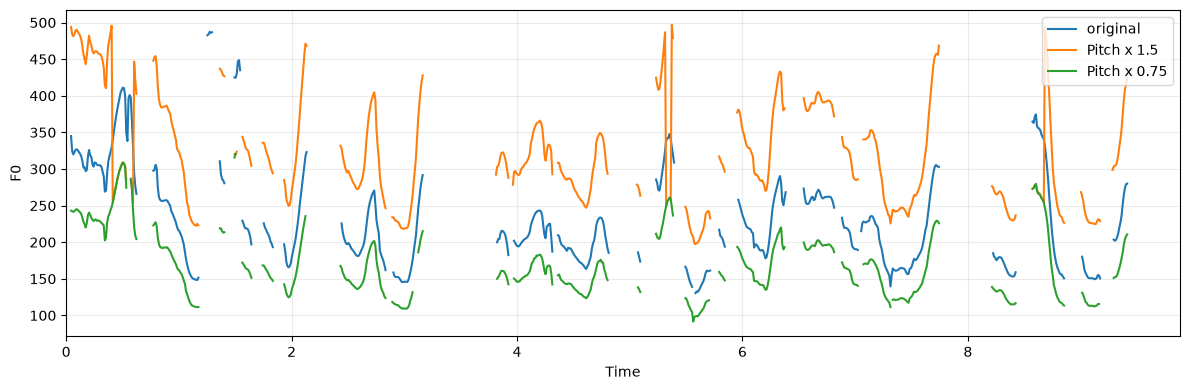

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))

plot_sample_name = [key for key in plot_contour.keys() if "clean_lj" in key][0]
plot_sample = plot_contour[plot_sample_name]

audio = AudioModifier(plot_sample_name)
xs = audio.snd.to_pitch(audio.time_step, audio.f0_min, audio.f0_max).xs()
for effect in plot_sample:
    if effect[0] == 'original_f0' or effect[0] == 'pitch':
        label = f"{effect[0].capitalize()} x {effect[1]}" if effect != ("original_f0", None) else "original"
        f0 = np.asarray(plot_sample[effect], dtype=float)

        f0[f0 == 0] = np.nan
        ax.plot(xs, f0, label=label)
ax.set_xlabel("Time")
ax.set_ylabel("F0")
ax.legend(loc="upper right", frameon=True)
ax.grid(True, alpha=0.25)
ax.set_xlim(left=0)
plt.tight_layout()
plt.show()

## Problem 1(b): PSOLA vs. resampling

## Problem 1(c): Your own voice